## ĐỀ BÀI - LINEAR REGRESSION 1 BIẾN


Giả sử bạn có dữ liệu về diện tích (m²) và giá bán (tỷ VNĐ) của 5 căn nhà. Hãy xây dựng mô hình Hồi quy tuyến tính (Linear Regression) để dự đoán giá của một căn nhà có diện tích là 80 m².

In [2]:
import numpy as np

# Khởi tạo dữ liệu
x = np.array([50, 60, 70, 90, 100])
y = np.array([1.5, 1.8, 2.1, 2.6, 3.0])

***CÁCH 1: SỬ DỤNG CÔNG THỨC TOÁN HỌC***

Mục tiêu là tìm đường thẳng $y = wx + b$ sao cho tổng bình phương sai số (MSE) giữa giá trị dự đoán và giá trị thực tế là nhỏ nhất.

Hàm mất mát cần tối ưu là:

$$
L(w, b) = \sum_{i=1}^{n} (y_i - (wx_i + b))^2
$$

Để tìm giá trị $w$ và $b$ làm cho $L$ nhỏ nhất, ta lấy đạo hàm riêng của $L$ theo từng biến và cho chúng bằng 0 (vì tại điểm cực tiểu, độ dốc bằng 0).

**Đạo hàm theo $b$:**

$$
\frac{\partial L}{\partial b} = -2 \sum_{i=1}^{n} (y_i - wx_i - b) = 0
$$

Từ đây ta rút ra được: $b = \bar{y} - w\bar{x}$

**Thay $b$ vừa tìm được vào phương trình đạo hàm theo $w$:**

$$
\frac{\partial L}{\partial w} = -2 \sum_{i=1}^{n} x_i (y_i - wx_i - (\bar{y} - w\bar{x})) = 0
$$

Sau khi biến đổi đại số từ phương trình đạo hàm theo $w$, ta thu được công thức:

$$
w = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2}
$$

In [3]:
# Tính trung bình
x_mean = np.mean(x)
y_mean = np.mean(y)

# Tính w và b theo công thức toán học
numerator = np.sum((x - x_mean) * (y - y_mean))
denominator = np.sum((x - x_mean)**2)

w = numerator / denominator
b = y_mean - w * x_mean

print(f"Toán học - Trọng số (w): {w:.4f}")
print(f"Toán học - Sai số (b): {b:.4f}")

Toán học - Trọng số (w): 0.0291
Toán học - Sai số (b): 0.0488


In [4]:
# Dự đoán cho 80m2
y_pred_math = w * 80 + b
print(f"Dự đoán giá nhà 80m2 (Toán học): {y_pred_math:.2f} tỷ VNĐ")

Dự đoán giá nhà 80m2 (Toán học): 2.37 tỷ VNĐ


***CÁCH 2: SỬ DỤNG THƯ VIỆN SCIKIT-LEARN***

In [5]:
!pip install scikit-learn
from sklearn.linear_model import LinearRegression

# Chuẩn bị dữ liệu (Sklearn yêu cầu đầu vào X là mảng 2 chiều)
X = x.reshape(-1, 1)

# Khởi tạo và huấn luyện mô hình (Giai đoạn Model Training)
model = LinearRegression()
model.fit(X, y)

# Lấy tham số w và b
w_sk = model.coef_[0]
b_sk = model.intercept_

print(f"Sklearn - Trọng số (w): {w_sk:.4f}")
print(f"Sklearn - Sai số (b): {b_sk:.4f}")

# Dự đoán (Giai đoạn Evaluation/Prediction)
y_pred_sk = model.predict([[80]])
print(f"Dự đoán giá nhà 80m2 (Sklearn): {y_pred_sk[0]:.2f} tỷ VNĐ")

Defaulting to user installation because normal site-packages is not writeable
Sklearn - Trọng số (w): 0.0291
Sklearn - Sai số (b): 0.0488
Dự đoán giá nhà 80m2 (Sklearn): 2.37 tỷ VNĐ


***ĐÁNH GIÁ SAI SỐ***

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Dự đoán lại toàn bộ tập dữ liệu ban đầu
y_all_pred = model.predict(X)

# Tính toán sai số
mse = mean_squared_error(y, y_all_pred)
mae = mean_absolute_error(y, y_all_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

Mean Squared Error (MSE): 0.0013
Mean Absolute Error (MAE): 0.0270


**ĐỀ BÀI - LINEAR REGRESSION ĐA BIẾN**

Công ty muốn xây dựng một công cụ tự động định giá nhà dựa trên các thuộc tính sẵn có để giúp nhân viên kinh doanh đưa ra báo giá nhanh chóng cho khách hàng dựa trên diện tích, số lượng phòng ngủ và khoảng cách so với trung tâm.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# Tạo dữ liệu giả lập
np.random.seed(42)
n_samples = 100

dientich = np.random.normal(100, 20, n_samples)      # m2
khoangcach = np.random.normal(10, 5, n_samples)     # km
phongngu = np.random.randint(1, 6, n_samples)       # 1-5 phòng

# Công thức thực tế để tạo y: Giá = 0.05*DT - 0.1*KC + 0.3*PN + 1 (tỷ VNĐ) + Nhiễu
y = 0.05 * dientich - 0.1 * khoangcach + 0.3 * phongngu + 1 + np.random.normal(0, 0.05, n_samples)

# Gộp vào DataFrame
X = np.column_stack((dientich, khoangcach, phongngu))
df = pd.DataFrame(X, columns=['DienTich', 'KhoangCach', 'PhongNgu'])
df['GiaNha'] = y

***CHUẨN BỊ DỮ LIỆU***

In [8]:
# Chia tập Train/Test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

***CÁCH 1: SỬ DỤNG GRADIENT DESCENT***

--- KẾT QUẢ VÒNG LẶP ---
Bias (b): 5.7800
Trọng số (w1, w2, w3): [ 0.92895179 -0.46457722  0.43825315]


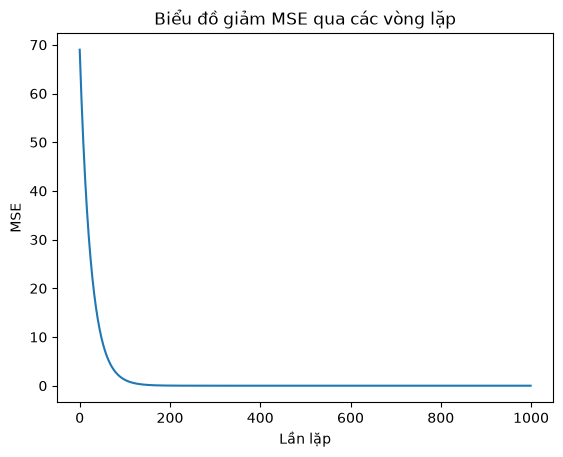

In [9]:
# Thêm cột 1 vào X để tính bias dễ dàng bằng ma trận
X_b = np.c_[np.ones((X_train_scaled.shape[0], 1)), X_train_scaled]
y_b = y_train.reshape(-1, 1)

# Khởi tạo tham số
n_iterations = 1000
learning_rate = 0.01
theta = np.random.randn(4, 1) # [b, w1, w2, w3]
m = len(X_b)
loss_history = []

# Vòng lặp tối ưu
for iteration in range(n_iterations):
    gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y_b)
    theta = theta - learning_rate * gradients

    # Tính MSE để theo dõi
    loss = np.mean((X_b.dot(theta) - y_b)**2)
    loss_history.append(loss)

print("--- KẾT QUẢ VÒNG LẶP ---")
print(f"Bias (b): {theta[0][0]:.4f}")
print(f"Trọng số (w1, w2, w3): {theta[1:].flatten()}")

# Vẽ biểu đồ giảm Loss
plt.plot(loss_history)
plt.title("Biểu đồ giảm MSE qua các vòng lặp")
plt.xlabel("Lần lặp"); plt.ylabel("MSE")
plt.show()

***CÁCH 2: DÙNG THƯ VIỆN SCIKIT-LEARN***

In [10]:
# Khởi tạo và huấn luyện
reg = LinearRegression()
reg.fit(X_train_scaled, y_train)

print("--- KẾT QUẢ SCIKIT-LEAR ---")
print(f"Bias b: {reg.intercept_:.4f}")
print(f"Trọng số w: {reg.coef_}")

# Dự đoán và đánh giá
y_pred = reg.predict(X_test_scaled)
mse_test = mean_squared_error(y_test, y_pred)
print(f"MSE trên tập Test: {mse_test:.4f}")

--- KẾT QUẢ SCIKIT-LEAR ---
Bias b: 5.7800
Trọng số w: [ 0.92895181 -0.4645772   0.43825314]
MSE trên tập Test: 0.0015


***INFERENCE MÔ HÌNH***

In [11]:
# 1. Dữ liệu nhà mới cần định giá
nha_moi = np.array([[120, 5, 3]])

# 2. Chuẩn hóa dữ liệu mới (Sử dụng scaler đã fit ở bước chuẩn bị)
nha_moi_scaled = scaler.transform(nha_moi)

# --- INFERENCE VỚI CÁCH 1 (THETA TỪ VÒNG LẶP) ---
# Thêm cột số 1 vào đầu để nhân ma trận với hệ số chặn b
nha_moi_b = np.c_[np.ones((1, 1)), nha_moi_scaled]
gia_du_doan_loop = nha_moi_b.dot(theta)

# --- INFERENCE VỚI CÁCH 2 (SCIKIT-LEARN) ---
gia_du_doan_sklearn = reg.predict(nha_moi_scaled)

print(f"--- KẾT QUẢ DỰ ĐOÁN CHO NHÀ {nha_moi[0][0]}m2, {nha_moi[0][1]}km, {nha_moi[0][2]}PN ---")
print(f"Giá dự đoán (Vòng lặp): {gia_du_doan_loop[0][0]:.3f} tỷ VNĐ")
print(f"Giá dự đoán (Sklearn):  {gia_du_doan_sklearn[0]:.3f} tỷ VNĐ")

--- KẾT QUẢ DỰ ĐOÁN CHO NHÀ 120m2, 5km, 3PN ---
Giá dự đoán (Vòng lặp): 7.390 tỷ VNĐ
Giá dự đoán (Sklearn):  7.390 tỷ VNĐ
